# Model selection: which churn model goes in front of a product manager, and how well does it really work?

**Governing question.** Seven model families have been built and compared on development data (notebooks 02–07). This notebook makes the final decision: **which model, with which decision rule**. It then opens the sealed test set **once** to measure how that frozen choice performs on 3,575 users it has never seen.

**Intended user.** A Waze product manager who needs one trustworthy churn-risk score, a clear rule for who gets a retention message, and an honest statement of what that rule will and will not achieve.

**Why selection is an estimation problem (lecture 16).** Every comparison on development data carries noise, and picking the best of many candidates on the same data makes the winner look better than it is. So the decision is made on development data, *then* frozen, and only then is the test set used, once, to estimate performance without that optimism.

**Road map.** §1 the frozen protocol → §2 development evidence → §3 calibration → §4 the decision rule → §5 one test evaluation → §6 errors and drivers → §7 results by user segment → §8 decision, monitoring, and rollback.

## 1. The frozen protocol

Everything in this table was fixed using development data only, before the test cells below were run.

| Decision | Choice | Reason |
| --- | --- | --- |
| Finalists | Softmax regression (λ = 0.1), boosted stumps (200 stages, η = 0.1), neural network (16 units, α = 0.01) | Best of their families (notebooks 02, 04, 07). The SVM is excluded because it gives no probabilities and trailed slightly; k-NN, trees, and forests ranked lower. |
| Selection rule | Highest paired development AP; ties (gap smaller than its fold-to-fold spread) go to the simplest, most interpretable model | A PM must be able to understand and question the score. |
| Decision rule | Flag a user when churn probability ≥ the **break-even probability** of the outreach economics | Ties the threshold to business value rather than an arbitrary metric. |
| Economics (illustrative) | $0.50 per contact, $10 value per saved user, 20% save rate | Placeholders a PM should replace; the effect of changing them is shown in §4. |
| Test-set use | One evaluation of the frozen model, plus the losing finalists and the baseline for context | No choice below depends on test results. |

**A note on test-set history.** Notebook 02 scored softmax regression on the test set once (AP 0.386), before any of the later families existed. No later decision used test data: notebooks 03–07 worked only on development folds. The final model chosen here is that same softmax configuration, so its test AP should match notebook 02, which is a useful consistency check.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, confusion_matrix, log_loss
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from dsm_project.algorithms import MajorityClassifier, create_student_algorithm
from dsm_project.artifacts import load_bundle
from dsm_project.churn_model import (
    DEFAULT_ECONOMICS,
    MODEL_NAME,
    MODEL_VERSION,
    train_churn_model,
)
from dsm_project.config import load_config
from dsm_project.data.waze import WazeChurnAdapter
from dsm_project.evaluation import (
    OutreachEconomics,
    best_value_threshold,
    bootstrap_metric_interval,
    brier_score,
    calibration_table,
    choose_threshold,
    expected_outreach_value,
    precision_recall_at,
)
from dsm_project.experiments import split_supervised_task
from dsm_project.segments import THREE_SEGMENT_NAMES, UserSegmenter
from dsm_project.visualization import OUTCOME_PALETTE, set_theme

set_theme()
CONFIG_PATH = Path("configs/waze.toml")
config = load_config(CONFIG_PATH)
dataset = WazeChurnAdapter().load(config)
split = split_supervised_task(dataset, config, task_name="classification")
dev_x, dev_y = split.train_features, split.train_targets
test_x, test_y = split.test_features, split.test_targets


def finalists():
    return {
        "softmax regression": make_pipeline(StandardScaler(), create_student_algorithm(
            "softmax_regression", l2_penalty=0.1, learning_rate=0.5)),
        "boosted stumps": create_student_algorithm(
            "gradient_boosting", n_estimators=200, learning_rate=0.1, max_depth=1),
        "neural network": make_pipeline(StandardScaler(), create_student_algorithm(
            "neural_network", hidden_layer_sizes=(16,), alpha=1e-2, random_state=0)),
    }


print(f"development users: {len(dev_x):,} | sealed test users: {len(test_x):,}")

development users: 10,724 | sealed test users: 3,575


## 2. Development evidence

The three finalists are compared on the same 15 development folds (5 folds × 3 repeats) for ranking, and on out-of-fold probabilities for **probability quality**: log loss (penalizes confident mistakes) and the Brier score (mean squared error of the probability). The baseline predicts the churn rate for everyone.

In [2]:
repeated = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=438)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=438)
fold_ap = {name: cross_val_score(model, dev_x, dev_y, cv=repeated, scoring="average_precision")
           for name, model in finalists().items()}
oof = {name: cross_val_predict(model, dev_x, dev_y, cv=cv, method="predict_proba")[:, 1]
       for name, model in finalists().items()}

base_rate = dev_y.mean()
rows = []
for name, scores in fold_ap.items():
    gap = scores - fold_ap["softmax regression"]
    rows.append({"model": name, "paired AP (mean)": scores.mean(),
                 "gap to softmax": gap.mean(), "sd of gap": gap.std(),
                 "log loss": log_loss(dev_y, oof[name]), "Brier": brier_score(dev_y, oof[name])})
rows.append({"model": "baseline (churn rate)", "paired AP (mean)": base_rate,
             "log loss": log_loss(dev_y, np.full(len(dev_y), base_rate)),
             "Brier": base_rate * (1 - base_rate)})
development = pd.DataFrame(rows).set_index("model")
display(development.round(4))

,paired AP (mean),gap to softmax,sd of gap,log loss,Brier
model,,,,,
softmax regression,0.3915,0.0000,0.0000,0.4090,0.1283
boosted stumps,0.3926,0.0011,0.0041,0.4082,0.1280
neural network,0.3914,-0.0001,0.0041,0.4066,0.1277
baseline (churn rate),0.1774,NaN,NaN,0.4674,0.1459


**Reading the evidence.** The three finalists are statistically indistinguishable: AP gaps of a few thousandths with fold-to-fold spreads of the same size, and nearly identical log loss and Brier scores, all clearly better than the baseline. By the frozen rule, the tie goes to the simplest, most interpretable model: **softmax regression**. Each of its coefficients is a readable change in log-odds (notebook 02).

## 3. Calibration: can the probabilities be taken at face value?

A cost-based threshold treats a score of 0.3 as "30% chance of churning". That is only valid if the model is **calibrated**. The reliability diagram groups development users into ten equal-sized groups by predicted probability (out-of-fold) and compares the average prediction with the observed churn rate.

group,1,2,3,4,5,6,7,8,9,10
mean predicted,0.046,0.067,0.086,0.109,0.136,0.168,0.207,0.251,0.306,0.399
observed rate,0.030,0.045,0.065,0.094,0.110,0.174,0.195,0.258,0.343,0.459
users,1073.000,1073.000,1073.000,1073.000,1072.000,1072.000,1072.000,1072.000,1072.000,1072.000


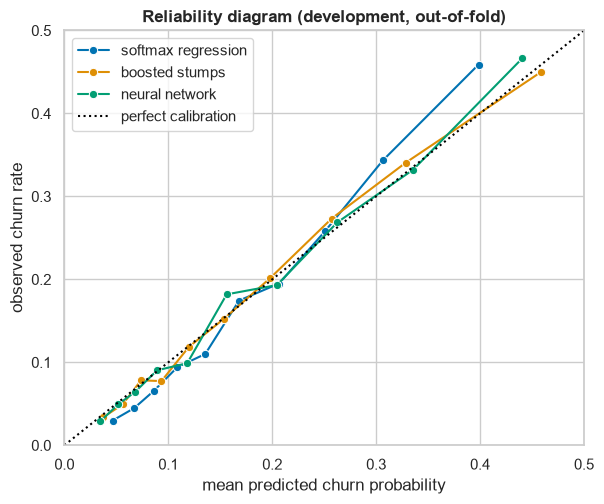

In [3]:
curves = pd.concat([
    calibration_table(dev_y, scores, bins=10).assign(model=name) for name, scores in oof.items()
])
fig, ax = plt.subplots(figsize=(6.2, 5.2))
sns.lineplot(data=curves, x="mean predicted", y="observed rate", hue="model", marker="o", ax=ax)
ax.plot([0, 0.5], [0, 0.5], ":", color="black", label="perfect calibration")
ax.set(xlim=(0, 0.5), ylim=(0, 0.5), xlabel="mean predicted churn probability",
       ylabel="observed churn rate", title="Reliability diagram (development, out-of-fold)")
ax.legend()
plt.tight_layout()
display(calibration_table(dev_y, oof["softmax regression"]).round(3).T)

All three models lie close to the diagonal, so their probabilities can be read at face value. The small deviations are systematic: in the top group softmax regression predicts about 0.40 where about 0.46 actually churn, so it is slightly under-confident for the highest-risk users and slightly over-confident at the low end. Deviations of a few percentage points do not change who should be contacted (§4), but the calibration check is repeated on the test set and belongs in monitoring.

## 4. The decision rule: who gets a retention message?

Contacting a user costs $c$. If that user would have churned, the message keeps them with probability $s$ (the save rate), which is worth $V$. For a user with churn probability $p$:

$$
\text{expected net value of contacting} = p \cdot s \cdot V - c ,
$$

which is positive exactly when $p \ge p^* = c / (sV)$, the **break-even probability**. With the illustrative economics ($c$ = $0.50, $V$ = $10, $s$ = 20%), $p^* = 0.25$.

The chart shows the realized net value per user on development data for every possible threshold, using out-of-fold probabilities.

,threshold,net value per user ($),share contacted,recall,precision
rule,,,,,
break-even (chosen),0.250,0.059,0.252,0.523,0.368
best on development,0.238,0.063,0.276,0.566,0.363
F2 (notebook 02),0.134,0.024,0.555,0.851,0.272


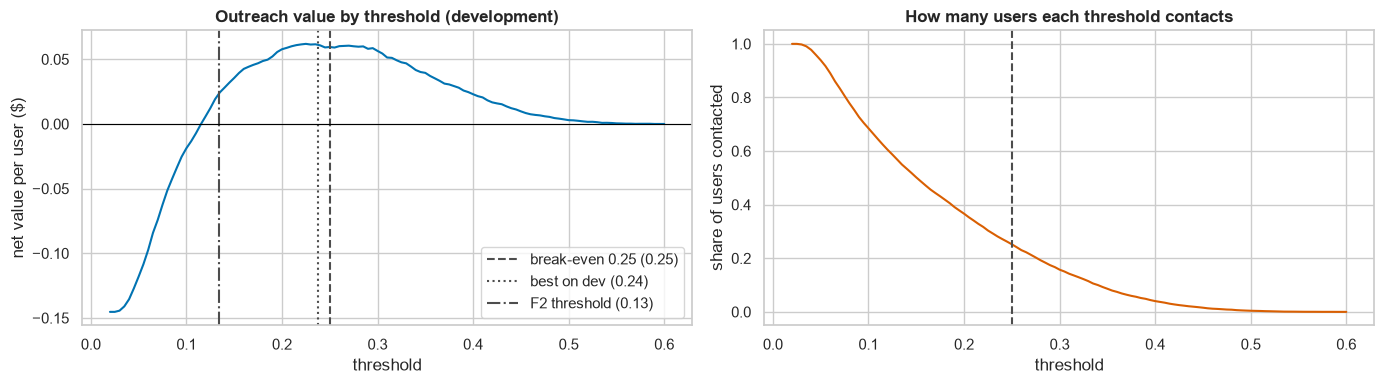

In [4]:
economics = DEFAULT_ECONOMICS
p_star = economics.break_even_probability
dev_scores = oof["softmax regression"]
grid = np.linspace(0.02, 0.6, 117)
value_curve = pd.DataFrame({
    "threshold": grid,
    "net value per user ($)": [expected_outreach_value(dev_y, dev_scores, t, economics) for t in grid],
    "share of users contacted": [float(np.mean(dev_scores >= t)) for t in grid],
})
best_t, best_v = best_value_threshold(dev_y, dev_scores, economics)
f2_t = choose_threshold(dev_y, dev_scores, beta=2.0).threshold

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.lineplot(data=value_curve, x="threshold", y="net value per user ($)", ax=axes[0])
for value, label, style in ((p_star, "break-even 0.25", "--"), (best_t, "best on dev", ":"),
                            (f2_t, "F2 threshold", "-.")):
    axes[0].axvline(value, linestyle=style, color="0.3", label=f"{label} ({value:.2f})")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].legend()
axes[0].set(title="Outreach value by threshold (development)")
sns.lineplot(data=value_curve, x="threshold", y="share of users contacted", ax=axes[1],
             color="#d95f02")
axes[1].axvline(p_star, linestyle="--", color="0.3")
axes[1].set(title="How many users each threshold contacts")
plt.tight_layout()

summary = pd.DataFrame([
    {"rule": name, "threshold": t,
     "net value per user ($)": expected_outreach_value(dev_y, dev_scores, t, economics),
     "share contacted": float(np.mean(dev_scores >= t)),
     "recall": precision_recall_at(dev_y, dev_scores, t)[1],
     "precision": precision_recall_at(dev_y, dev_scores, t)[0]}
    for name, t in (("break-even (chosen)", p_star), ("best on development", best_t),
                    ("F2 (notebook 02)", f2_t))
]).set_index("rule")
display(summary.round(3))

**Reading the curve.** Value rises as the threshold moves up from very low values (fewer wasted contacts), peaks near the break-even point, and falls toward zero as fewer churners are reached. The break-even rule captures nearly all of the best achievable value without being fitted to the data. The empirical best threshold is itself a tuned quantity, so using it would carry selection optimism. The F2 rule from notebook 02 contacts more than half of all users and, under these economics, earns less than half as much ($0.024 versus $0.059 per user).

**The economics matter more than the model.** The table shows the break-even rule under other assumptions a PM might hold:

In [5]:
scenarios = []
for save_rate in (0.1, 0.2, 0.3):
    for value in (5.0, 10.0, 20.0):
        scenario = OutreachEconomics(cost_per_contact=0.5, value_per_saved_user=value,
                                     save_rate=save_rate)
        threshold = scenario.break_even_probability
        scenarios.append({
            "save rate": f"{save_rate:.0%}", "value per saved user ($)": value,
            "break-even threshold": threshold,
            "share contacted": float(np.mean(dev_scores >= threshold)),
            "net value per 1,000 users ($)": 1000 * expected_outreach_value(
                dev_y, dev_scores, threshold, scenario),
        })
display(pd.DataFrame(scenarios).set_index(["save rate", "value per saved user ($)"]).round(3))

break-even threshold  share contacted  \
save rate value per saved user ($)                                          
10%       5.0                                      1.000            0.000   
          10.0                                     0.500            0.004   
          20.0                                     0.250            0.252   
20%       5.0                                      0.500            0.004   
          10.0                                     0.250            0.252   
          20.0                                     0.125            0.587   
30%       5.0                                      0.333            0.109   
          10.0                                     0.167            0.452   
          20.0                                     0.083            0.762   

                                    net value per 1,000 users ($)  
save rate value per saved user ($)                                 
10%       5.0                                               0.000  
          10.0                                              0.420  
          20.0                                             59.493  
20%       5.0                                               0.420  
          10.0                                             59.493  
          20.0                                            317.838  
30%       5.0                                              20.328  
          10.0                                            180.250  
          20.0                                            626.259

If outreach rarely changes behavior (10% save rate) and a user is worth little ($5), outreach barely pays at any threshold. If the save rate is 30% and a user is worth $20, it pays to contact most of the user base. **The most valuable next measurement for the PM is the real save rate, from an A/B test of the retention message**, not a better model.

**Frozen decision:** softmax regression (λ = 0.1), threshold $p^* = 0.25$ under the illustrative economics.

## 5. One evaluation on the sealed test set

The package function `train_churn_model` fits the frozen model on the development users, scores the test users once through the shared evaluation boundary, and saves a **versioned model bundle** (model file plus metadata). Everything below is computed from the *saved bundle*, so the numbers describe exactly the model the product will serve. The losing finalists and the baseline are scored on the same test users for context.

In [6]:
bundle_dir = train_churn_model(CONFIG_PATH, Path("artifacts") / f"{MODEL_NAME}-{MODEL_VERSION}")
bundle = load_bundle(bundle_dir)
threshold = bundle.metadata["decision_threshold"]
features = list(bundle.metadata["feature_names"])
test_probability = bundle.estimator.predict_proba(test_x[features])[:, 1]
test_flag = bundle.estimator.predict(test_x[features])
observed = test_y.to_numpy()

print(f"bundle: {bundle_dir} | version {bundle.metadata['model_version']} | "
      f"threshold {threshold:.2f} | data sha256 {bundle.metadata['data_sha256'][:12]}…")


def interval(metric, scores):
    found = bootstrap_metric_interval(observed, scores, metric, resamples=2000)
    return f"{found.estimate:.3f} ({found.lower:.3f}–{found.upper:.3f})"


final_rows = {
    "average precision": interval(average_precision_score, test_probability),
    "recall at threshold": interval(lambda o, p: precision_recall_at(o, p, threshold)[1],
                                    test_probability),
    "precision at threshold": interval(lambda o, p: precision_recall_at(o, p, threshold)[0],
                                       test_probability),
    "share of users contacted": f"{np.mean(test_flag):.3f}",
    "net value per 1,000 users ($)": interval(
        lambda o, p: 1000 * expected_outreach_value(o, p, threshold, economics), test_probability),
    "Brier score (baseline)": f"{brier_score(observed, test_probability):.4f} "
                              f"({observed.mean() * (1 - observed.mean()):.4f})",
}
display(pd.Series(final_rows, name="final model on test users (95% bootstrap CI)").to_frame())

bundle: artifacts/student-softmax-churn-1.0.0 | version 1.0.0 | threshold 0.25 | data sha256 958330c53952…


,final model on test users (95% bootstrap CI)
average precision,0.386 (0.351–0.426)
recall at threshold,0.546 (0.505–0.585)
precision at threshold,0.375 (0.344–0.407)
share of users contacted,0.258
"net value per 1,000 users ($)",64.615 (47.969–81.122)
Brier score (baseline),0.1277 (0.1459)


In [7]:
context = []
for name, model in {**finalists(), "baseline (always retained)": MajorityClassifier()}.items():
    fitted = model.fit(dev_x, dev_y)
    if name.startswith("baseline"):
        scores = np.full(len(observed), dev_y.mean())
    else:
        scores = fitted.predict_proba(test_x)[:, 1]
    precision, recall = precision_recall_at(observed, scores, threshold)
    context.append({"model": name, "test AP": average_precision_score(observed, scores),
                    "recall @ 0.25": recall, "precision @ 0.25": precision,
                    "share contacted": float(np.mean(scores >= threshold)),
                    "net value / 1,000 users ($)": 1000 * expected_outreach_value(
                        observed, scores, threshold, economics),
                    "Brier": brier_score(observed, scores)})
display(pd.DataFrame(context).set_index("model").round(3))

,test AP,recall @ 0.25,precision @ 0.25,share contacted,"net value / 1,000 users ($)",Brier
model,,,,,,
softmax regression,0.386,0.546,0.375,0.258,64.615,0.128
boosted stumps,0.380,0.566,0.378,0.265,68.112,0.127
neural network,0.388,0.590,0.368,0.284,67.133,0.127
baseline (always retained),0.177,0.000,0.000,0.000,0.000,0.146


**Reading the test results.**

- The frozen softmax model ranks unseen users with **AP 0.386** (95% interval 0.35–0.43): the same value as notebook 02's test score and in line with development (≈ 0.39). No selection optimism shows up.
- At the 0.25 threshold it contacts about a quarter of users (26%) and reaches about 55% of all churners. About 37% of contacts go to real churners, roughly twice the hit rate of random outreach (18%).
- Under the illustrative economics that is worth about **$65 per 1,000 users** (95% interval $48–81). The size, and even the sign, depend on the save rate (§4).
- The losing finalists score within about 0.006 AP of the winner on the test set too. The tie seen in development holds on unseen users, so the choice of the simpler model costs nothing.

## 6. Errors and drivers

### 6.1 Confusion matrix

The decision is binary, so the confusion matrix shows exactly whom the rule contacts and whom it misses.

churners reached 346 of 634; contacts wasted on retained users 576; churners missed 288


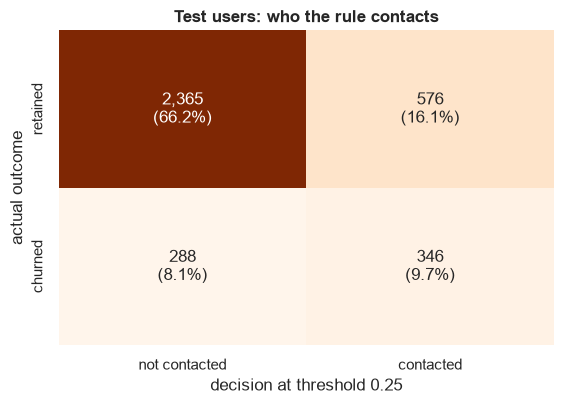

In [8]:
matrix = confusion_matrix(observed, test_flag, labels=[0, 1])
labels = np.array([[f"{count:,}\n({count / matrix.sum():.1%})" for count in row] for row in matrix])
fig, ax = plt.subplots(figsize=(5.8, 4.2))
sns.heatmap(matrix, annot=labels, fmt="", cmap="Oranges", cbar=False, ax=ax,
            xticklabels=["not contacted", "contacted"], yticklabels=["retained", "churned"])
ax.set(xlabel="decision at threshold 0.25", ylabel="actual outcome",
       title="Test users: who the rule contacts")
plt.tight_layout()
tn, fp, fn, tp = matrix.ravel()
print(f"churners reached {tp:,} of {tp + fn:,}; contacts wasted on retained users {fp:,}; "
      f"churners missed {fn:,}")

In a PM's terms: about half of the churners are reached, and about two of every three messages go to users who would have stayed. With a $0.50 message that waste is affordable, which is exactly what the break-even rule accounts for. The missed churners are mostly users still active this month (notebooks 02–07), which no model built on this data can see.

### 6.2 Calibration on unseen users

group,1,2,3,4,5,6,7,8,9,10
mean predicted,0.047,0.067,0.087,0.111,0.138,0.171,0.209,0.254,0.311,0.401
observed rate,0.025,0.045,0.075,0.073,0.123,0.162,0.190,0.263,0.345,0.473
users,358.000,358.000,358.000,358.000,358.000,357.000,357.000,357.000,357.000,357.000


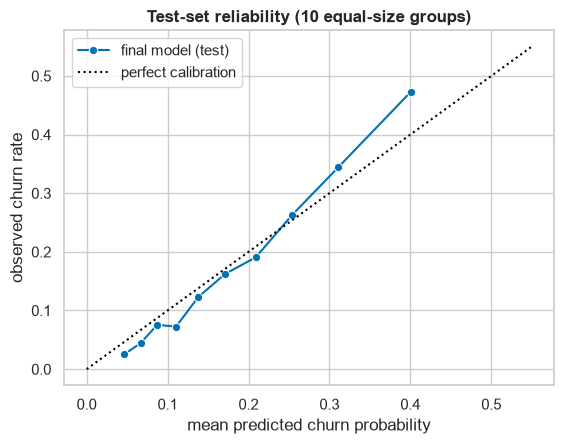

In [9]:
test_curve = calibration_table(observed, test_probability, bins=10)
fig, ax = plt.subplots(figsize=(5.8, 4.6))
sns.lineplot(data=test_curve, x="mean predicted", y="observed rate", marker="o", ax=ax,
             label="final model (test)")
ax.plot([0, 0.55], [0, 0.55], ":", color="black", label="perfect calibration")
ax.set(xlabel="mean predicted churn probability", ylabel="observed churn rate",
       title="Test-set reliability (10 equal-size groups)")
ax.legend()
plt.tight_layout()
display(test_curve.round(3).T)

On unseen users the probabilities remain close to the diagonal, with the same mild under-confidence at the top. With about 360 users per group, a deviation of a few points is within sampling noise. The cost-based threshold remains valid.

### 6.3 What drives the score: permutation importance

Permutation importance shuffles one feature at a time on the test users and measures how much average precision drops. Unlike coefficients, it is measured on unseen data and in the units the PM cares about (ranking quality).

,AP drop,sd
feature,,
activity_days,0.0709,0.0132
driving_days,0.0464,0.0131
n_days_after_onboarding,0.0401,0.0085
total_navigations_fav1,0.0116,0.0045
duration_minutes_drives,0.0050,0.0013
total_navigations_fav2,0.0037,0.0013
driven_km_drives,0.0001,0.0003
total_sessions,-0.0002,0.0007
is_iphone,-0.0004,0.0004


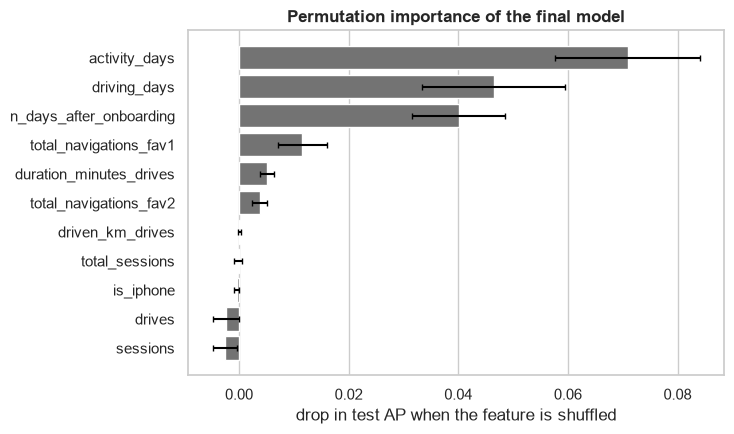

In [10]:
importance = permutation_importance(bundle.estimator, test_x[features], observed,
                                    scoring="average_precision", n_repeats=10, random_state=438)
ranking = pd.DataFrame({"feature": features, "AP drop": importance.importances_mean,
                        "sd": importance.importances_std}).sort_values("AP drop", ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.barplot(data=ranking, x="AP drop", y="feature", color="0.45", ax=ax)
ax.errorbar(ranking["AP drop"], np.arange(len(ranking)), xerr=ranking["sd"], fmt="none",
            ecolor="black", capsize=2)
ax.set(xlabel="drop in test AP when the feature is shuffled", ylabel="",
       title="Permutation importance of the final model")
plt.tight_layout()
display(ranking.set_index("feature").round(4))

Active days matter most (shuffling them costs about 0.07 AP), followed by driving days and tenure (about 0.04–0.05 each). Favorite-place navigations add a little (about 0.01); every other feature changes test AP by about nothing. On unseen users the model's ranking rests on **how often people use Waze and how long they have used it**, the same story as every earlier notebook and my earlier analysis. Because active days and driving days are strongly correlated, shuffling one leaves part of its signal in the other, so their individual importances understate their combined role.

## 7. Results by user segment

The PM will see each user's segment next to their risk score. How does the decision rule behave within each segment? Segments come from `UserSegmenter` fitted on development users only.

In [11]:
segmenter = UserSegmenter(3, random_state=438).fit(dev_x)
test_segment = segmenter.predict(test_x)
by_segment = []
for name in THREE_SEGMENT_NAMES:
    mask = (test_segment == name).to_numpy()
    precision, recall = precision_recall_at(observed[mask], test_probability[mask], threshold)
    by_segment.append({"segment": name, "test users": int(mask.sum()),
                       "churn rate": observed[mask].mean(),
                       "share contacted": float(np.mean(test_flag[mask])),
                       "recall": recall, "precision": precision,
                       "share of all churners reached": float(
                           np.sum(test_flag[mask] & (observed[mask] == 1)) / observed.sum())})
display(pd.DataFrame(by_segment).set_index("segment").round(3))

,test users,churn rate,share contacted,recall,precision,share of all churners reached
segment,,,,,,
Occasional users,719,0.373,0.828,0.899,0.405,0.380
Steady light users,1034,0.121,0.102,0.232,0.276,0.046
Steady heavy users,1822,0.132,0.122,0.315,0.342,0.120


**Insights.**

- **Occasional users** are where the rule does most of its work: most of them are contacted, and most of the churners it reaches come from this segment.
- **Steady light and heavy users** are rarely contacted. Their churners are mostly the active churners the model cannot see.
- For a PM this suggests two different plays: **automated, score-based outreach for occasional users**, and, for steady users, **product-quality monitoring and research** rather than messaging, since the score cannot find their churners.

## 8. Decision, monitoring, and rollback

**Promotion decision.** Promote **`student-softmax-churn` 1.0.0**: student softmax regression (λ = 0.1) on the 11 raw usage features, flagging users at churn probability ≥ 0.25. It is saved at `artifacts/student-softmax-churn-1.0.0/` with metadata recording the threshold policy, test metrics, data checksum, and source revision, and can be rebuilt with `uv run python scripts/train_churn_model.py`.

**What the evidence supports.** On unseen users the model ranks churn risk about twice as well as random outreach (AP ≈ 0.39) and its probabilities are calibrated, so a cost-based threshold is meaningful. **What it does not support:** early warning (activity and churn come from the same month), reaching churners who are still active, or any causal claim about what retention messages achieve.

**Monitoring (for milestone 7).**

- Input drift: compare the distributions of active days, driving days, and tenure against the development data. A shift in active days moves the whole score.
- Score drift: the share of users above 0.25 (about 25% at launch).
- Calibration and recall once churn labels arrive: re-run the reliability check monthly.

**Rollback.** Keep the previous bundle directory. If monitoring flags a problem, point the service back at the previous version. Version 1.0.0 is the first churn model, so its fallback is "no automated outreach".

**Next steps.** Milestone 6: serve this bundle through the API (risk score, flag, and segment for each user), log predictions to SQLite, and rebuild the Streamlit app on top of it.